# 04 — Model training, user-independent evaluation and ablation
PRD §12–14, §17, §19–20. All splits are grouped by `user_id`: test users never appear in training.

This notebook reads the results written by `python -m src.model` (about 5 minutes) instead of retraining everything, so it opens and re-runs quickly.

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config, cleaning, features, baseline
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')
config.FIG_DIR.mkdir(parents=True, exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(config.FIG_DIR / f'{name}.png', dpi=130)
from src import model
from IPython.display import Image, display
res = json.loads((config.REPORT_DIR / 'results.json').read_text())
win = pd.read_csv(config.WINDOW_PATH, parse_dates=['window_start'])
print(res['n_windows'], 'windows,', win.user_id.nunique(), 'users, mean label purity', round(res['label_purity_mean'], 3))
print('window labels:', res['window_label_distribution'])

1000 windows, 50 users, mean label purity 0.318
window labels: {'calm': 0.63, 'stressed': 0.187, 'positive': 0.156, 'low': 0.027}


## Ablation: A (raw) → B (+personal baseline) → C (+temporal) → E (C + optional extended features)
5-fold GroupKFold: each fold trains on 40 users and tests on 10 unseen users. Accuracy is misleading because most windows are labelled calm, so **balanced accuracy (chance = 0.25)** and **macro-F1** are the headline metrics.

In [2]:
cv = pd.DataFrame(res['cross_validation'])
cv[['feature_set','model','accuracy_mean','balanced_accuracy_mean','balanced_accuracy_std','macro_f1_mean']].round(3)

,feature_set,model,accuracy_mean,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean
0,-,majority_class,0.630,0.250,0.000,0.193
1,A_raw,random_forest,0.436,0.269,0.021,0.263
2,A_raw,xgboost,0.417,0.252,0.032,0.245
3,A_raw,svm,0.332,0.294,0.081,0.242
4,B_+baseline,random_forest,0.493,0.284,0.031,0.281
5,B_+baseline,xgboost,0.492,0.291,0.018,0.289
6,B_+baseline,svm,0.382,0.313,0.029,0.271
7,C_+baseline+temporal,random_forest,0.500,0.288,0.017,0.288
8,C_+baseline+temporal,xgboost,0.496,0.278,0.018,0.276
9,C_+baseline+temporal,svm,0.384,0.302,0.034,0.269


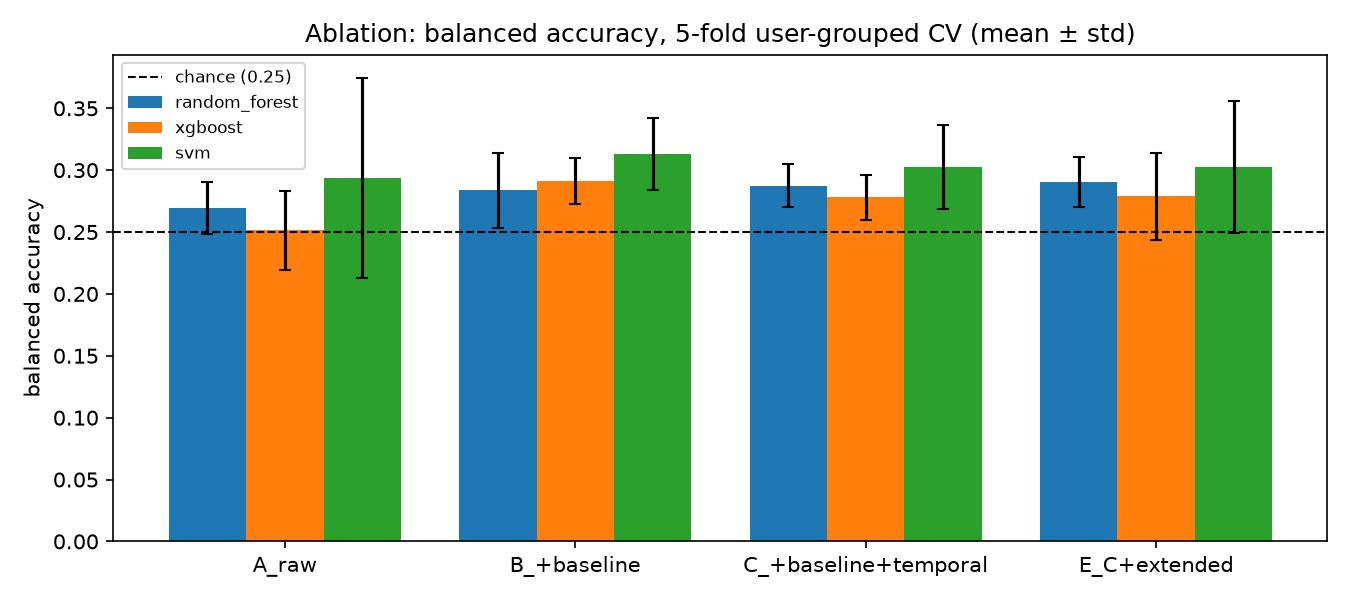

In [3]:
display(Image(config.FIG_DIR / 'ablation.png', width=700))

## Is the model better than chance?
Permutation test: labels are shuffled 200 times and the whole grouped CV is re-run (XGBoost, feature set C).

In [4]:
res['permutation_test']

{'feature_set': 'C_+baseline+temporal',
 'metric': 'balanced_accuracy',
 'score': 0.2780485119699375,
 'permuted_mean': 0.2488923199580335,
 'permuted_95th': 0.2699906118520964,
 'p_value': 0.01990049751243781,
 'n_permutations': 200}

## Leave-one-user-out (PRD §14, advanced)

In [5]:
pd.DataFrame(res['leave_one_user_out']).round(3)

,model,feature_set,accuracy,balanced_accuracy,macro_f1
0,majority_class,C_+baseline+temporal,0.630,0.250,0.193
1,random_forest,C_+baseline+temporal,0.499,0.296,0.294
2,xgboost,C_+baseline+temporal,0.480,0.279,0.274
3,svm,C_+baseline+temporal,0.359,0.283,0.259


## Option B: valence/arousal regression (window means)

In [6]:
pd.DataFrame(res['regression']).T.round(4)

,mae,rmse,r2
valence/mean_predictor,0.0407,0.0504,-0.0019
valence/xgboost,0.0431,0.0534,-0.1236
arousal/mean_predictor,0.0338,0.0426,-0.0038
arousal/xgboost,0.0329,0.0418,0.0315


## Final models on a 40/10 user split

In [7]:
hold = res['holdout']
print('test users:', hold['test_users'])
for name in ['random_forest', 'xgboost', 'svm']:
    print(f'{name:14s}', {k: round(v, 3) for k, v in hold[name].items() if isinstance(v, float)})
print('majority-class accuracy on these test users:', round(hold['majority_class_on_test'], 3))
pd.DataFrame(hold['xgboost']['report']).T.round(3)

test users: ['U014', 'U018', 'U020', 'U026', 'U027', 'U031', 'U033', 'U040', 'U046', 'U049']
random_forest  {'accuracy': 0.485, 'balanced_accuracy': 0.266, 'macro_f1': 0.26}
xgboost        {'accuracy': 0.48, 'balanced_accuracy': 0.262, 'macro_f1': 0.262}
svm            {'accuracy': 0.355, 'balanced_accuracy': 0.225, 'macro_f1': 0.228}
majority-class accuracy on these test users: 0.62


,precision,recall,f1-score,support
calm,0.659,0.653,0.656,124.00
positive,0.133,0.121,0.127,33.00
stressed,0.256,0.275,0.265,40.00
low,0.000,0.000,0.000,3.00
accuracy,0.480,0.480,0.480,0.48
macro avg,0.262,0.262,0.262,200.00
weighted avg,0.481,0.480,0.481,200.00


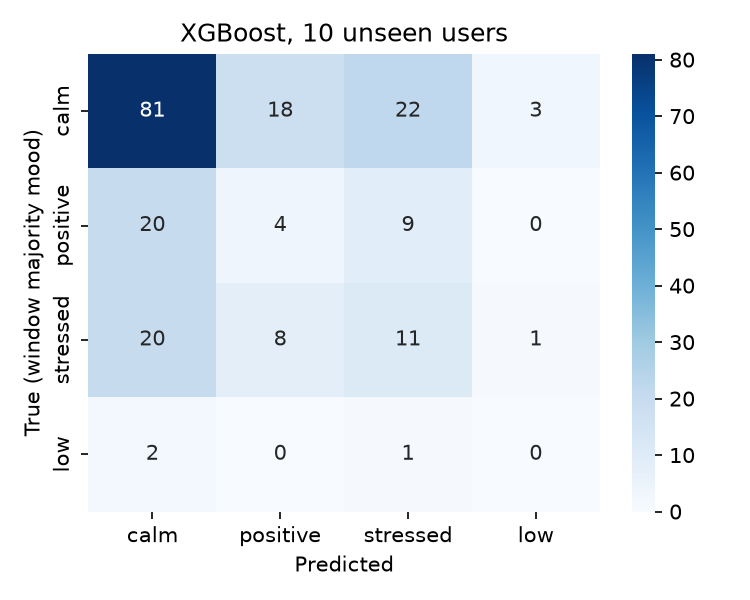

In [8]:
display(Image(config.FIG_DIR / 'confusion_matrix.png', width=420))

## ML explanation layer: feature importance and SHAP (PRD §17)

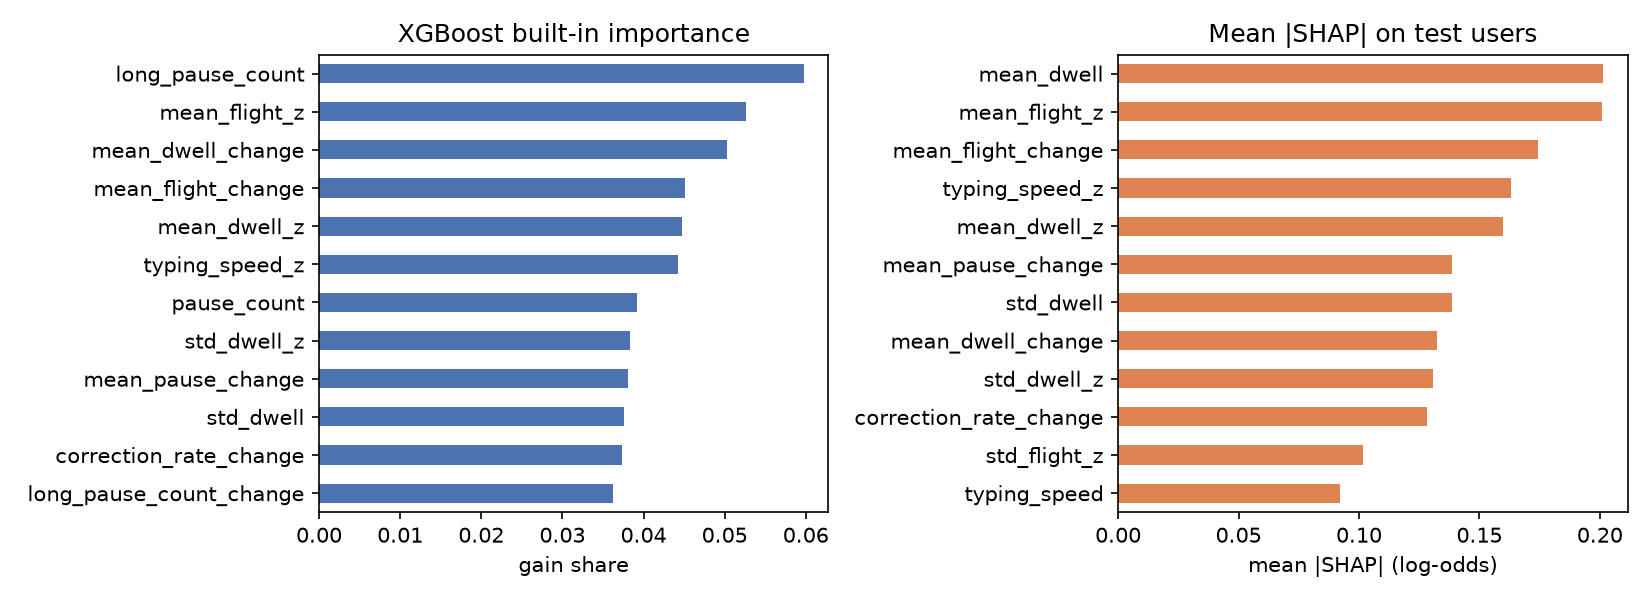

,gain,mean_abs_shap
mean_dwell,0.0353,0.2014
mean_flight_z,0.0526,0.2009
mean_flight_change,0.0451,0.1744
typing_speed_z,0.0442,0.1630
mean_dwell_z,0.0447,0.1598
mean_pause_change,0.0381,0.1385
std_dwell,0.0376,0.1384
mean_dwell_change,0.0503,0.1323
std_dwell_z,0.0383,0.1308
correction_rate_change,0.0373,0.1282


In [9]:
display(Image(config.FIG_DIR / 'feature_importance.png', width=800))
pd.DataFrame({'gain': hold['xgboost_importance'], 'mean_abs_shap': hold['xgboost_shap']}).sort_values('mean_abs_shap', ascending=False).head(10).round(4)

## LLM explanation layer (PRD §15–16, §19.4)
Written by `python -m src.llm`. `source` shows whether the LLM (Groq or Claude) or the offline template produced each explanation; `grounding` is the automatic §19.4 check.

In [10]:
p = config.REPORT_DIR / 'llm_explanations.json'
exps = json.loads(p.read_text()) if p.exists() else []
for e in exps:
    print(f"[{e['source'][:30]}] true={e['true_window_mood']} -> {e['explanation']['predicted_state']} ({e['explanation']['confidence']})")
    print('  ', e['explanation']['explanation'])
pd.DataFrame([e['grounding'] for e in exps])

[template] true=stressed -> positive (low)
   The classifier suggests 'positive' (p=0.55). The largest departures from this user's usual typing are: flight variability below baseline (-1.3 SD); key hold (dwell) time above baseline (+1.1 SD); correction (backspace) rate above baseline (+0.9 SD).
[template] true=low -> calm (low)
   The classifier suggests 'calm' (p=0.64). The largest departures from this user's usual typing are: correction (backspace) rate below baseline (-1.5 SD); key hold (dwell) time above baseline (+1.3 SD); number of long pauses below baseline (-1.0 SD).
[template] true=calm -> positive (low)
   The classifier suggests 'positive' (p=0.51). The largest departures from this user's usual typing are: correction (backspace) rate below baseline (-1.5 SD); time between keys (flight) above baseline (+1.3 SD); flight variability above baseline (+0.8 SD).
[template] true=positive -> stressed (low)
   The classifier suggests 'stressed' (p=0.42). The largest departures from th

,features_referenced,references_any_feature,matches_ml_state,claims_agreement,confidence_label,mentions_uncertainty,diagnostic_language
0,"[mean_dwell, mean_flight, std_flight, correcti...",True,True,True,low,True,False
1,"[mean_dwell, pause_count, long_pause_count, co...",True,True,True,low,True,False
2,"[mean_flight, std_flight, correction_rate]",True,True,True,low,True,False
3,"[mean_dwell, std_dwell, mean_pause, pause_count]",True,True,True,low,True,False
4,"[mean_dwell, std_dwell, mean_pause, pause_count]",True,True,True,low,True,False
5,"[mean_dwell, std_dwell, mean_flight, std_fligh...",True,True,True,low,True,False
6,"[typing_speed, mean_pause, pause_count]",True,True,True,low,True,False
7,"[typing_speed, mean_pause, pause_count]",True,True,True,low,True,False


## Pipeline validation on the generated dataset
The same code run with `MOOD_RUN=generated` on data from `src/data_generator.py` (one mood per session). This checks that the pipeline *can* recover a signal when the labels are coherent; it says nothing about real people.

In [11]:
gp = config.ROOT / 'reports/generated/results.json'
if gp.exists():
    g = json.loads(gp.read_text())
    both = pd.DataFrame(res['cross_validation']).merge(pd.DataFrame(g['cross_validation']), on=['feature_set','model'], suffixes=('_provided','_generated'))
    display(both[['feature_set','model','balanced_accuracy_mean_provided','balanced_accuracy_mean_generated','macro_f1_mean_provided','macro_f1_mean_generated']].round(3))
    print('generated permutation test:', g['permutation_test'])

,feature_set,model,balanced_accuracy_mean_provided,balanced_accuracy_mean_generated,macro_f1_mean_provided,macro_f1_mean_generated
0,-,majority_class,0.250,0.250,0.193,0.119
1,A_raw,random_forest,0.269,0.542,0.263,0.515
2,A_raw,xgboost,0.252,0.532,0.245,0.506
3,A_raw,svm,0.294,0.560,0.242,0.541
4,B_+baseline,random_forest,0.284,0.777,0.281,0.762
5,B_+baseline,xgboost,0.291,0.726,0.289,0.713
6,B_+baseline,svm,0.313,0.757,0.271,0.744
7,C_+baseline+temporal,random_forest,0.288,0.773,0.288,0.761
8,C_+baseline+temporal,xgboost,0.278,0.757,0.276,0.745
9,C_+baseline+temporal,svm,0.302,0.755,0.269,0.742


generated permutation test: {'feature_set': 'C_+baseline+temporal', 'metric': 'balanced_accuracy', 'score': 0.7567819765442538, 'permuted_mean': 0.2665232780658672, 'permuted_95th': 0.2898152707546577, 'p_value': 0.004975124378109453, 'n_permutations': 200}


## Conclusions (synthetic benchmark only)
| Hypothesis | Provided dataset | Generated dataset | Verdict |
|---|---|---|---|
| **H1** keystroke features carry mood information | Best balanced accuracy 0.29–0.31 vs 0.25 chance; permutation p ≈ 0.02 | 0.54–0.56 with raw features alone | Supported, but the provided data's signal is very weak at window level |
| **H2** personal baselines help | +0.01 to +0.04 (within fold noise) | **+0.19 to +0.24** (A → B) | Supported on coherent labels; inconclusive on the provided data |
| **H3** temporal trends help | No gain (B → C) | No gain (B → C) | Not supported |
| **H4** LLM gives grounded explanations | All sampled explanations reference real features and avoid diagnosis | same | Template path verified; live LLM run (Groq) pending |

Personalisation is the component that matters. Temporal *change* features do not help, even on the generated data where mood persists across sessions. A likely reason is that a change score is near zero whenever the mood stays the same, so it carries little information about which mood it is. The optional extended features (E) add nothing on either dataset.

None of these numbers describe real people: both datasets are synthetic and their labels are generator assumptions.